
# Customer Segmentation Using Clustering Algorithms

## Introduction

Customer segmentation is an unsupervised machine learning technique used to group observations with similar characteristics.

This project applies K-Means and Agglomerative Hierarchical Clustering to discover patterns in the selected customer dataset.

## Objectives

- Understand and explore the dataset.
- Clean the data and prepare appropriate clustering features.
- Apply feature scaling.
- Determine a suitable number of clusters.
- Implement K-Means and Agglomerative Hierarchical Clustering.
- Compare hierarchical linkage strategies.
- Evaluate the models using internal clustering metrics.
- Visualize clusters using PCA and t-SNE.
- Interpret the resulting clusters and summarize the findings.

## Algorithms

1. K-Means Clustering
2. Agglomerative Hierarchical Clustering

## Evaluation Metrics

- Silhouette Score
- Davies-Bouldin Index
- Calinski-Harabasz Index

## Reproducibility

A random state of 42 will be used wherever applicable to make results reproducible.


## Import libraries

In [2]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.



## Load the Dataset


In [3]:

# Update this filename to match the CSV inside your data folder.
DATA_PATH = Path("../data/Customer_Data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Please update DATA_PATH to your actual CSV filename."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully.
Number of rows: 8950
Number of columns: 18


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



## Dataset Description

The dataset contains customer-related observations and attributes that will be examined to identify groups with similar characteristics.

Before fitting the clustering algorithms, we will inspect the columns, data types, missing values, duplicate records and statistical distributions.

Any ground-truth category, when available, will be kept separate from the features used to fit the clustering models.



## Dataset audit

In [4]:

print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null 

,Data Type
CUST_ID,object
BALANCE,float64
BALANCE_FREQUENCY,float64
PURCHASES,float64
ONEOFF_PURCHASES,float64
INSTALLMENTS_PURCHASES,float64
CASH_ADVANCE,float64
PURCHASES_FREQUENCY,float64
ONEOFF_PURCHASES_FREQUENCY,float64
PURCHASES_INSTALLMENTS_FREQUENCY,float64



Missing values:


,Missing Values
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CUST_ID,8950,8950,C10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BALANCE,8950.0,NaN,NaN,NaN,1564.474828,2081.531879,0.0,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,NaN,NaN,NaN,0.877271,0.236904,0.0,0.888889,1.0,1.0,1.0
PURCHASES,8950.0,NaN,NaN,NaN,1003.204834,2136.634782,0.0,39.635,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,NaN,NaN,NaN,592.437371,1659.887917,0.0,0.0,38.0,577.405,40761.25
INSTALLMENTS_PURCHASES,8950.0,NaN,NaN,NaN,411.067645,904.338115,0.0,0.0,89.0,468.6375,22500.0
CASH_ADVANCE,8950.0,NaN,NaN,NaN,978.871112,2097.163877,0.0,0.0,0.0,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,NaN,NaN,NaN,0.490351,0.401371,0.0,0.083333,0.5,0.916667,1.0
ONEOFF_PURCHASES_FREQUENCY,8950.0,NaN,NaN,NaN,0.202458,0.298336,0.0,0.0,0.083333,0.3,1.0
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,NaN,NaN,NaN,0.364437,0.397448,0.0,0.0,0.166667,0.75,1.0



## Data Cleaning 
Data quality is important because missing values and duplicate observations can affect the clustering structure.

Duplicate records will be removed. Missing numerical values will be replaced with the median of their respective columns, while missing categorical values will be filled with the mode where available.

Potential outliers will be inspected before deciding how to handle them. Values will not be deleted merely because they are unusually high or low, since they may represent genuine customer behavior.


## Handle missing values and duplicates

In [5]:

df_clean = df.copy()

# Remove duplicate observations
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Fill missing values using an appropriate strategy
for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].median()
            )
        else:
            mode_values = df_clean[col].mode()
            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0]
                )
            else:
                df_clean[col] = df_clean[col].fillna("Unknown")

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicate rows:", df_clean.duplicated().sum())


Original shape: (8950, 18)
Cleaned shape: (8950, 18)
Remaining missing values: 0
Remaining duplicate rows: 0



##  Exploratory Data Analysis (EDA)

EDA helps reveal the distribution and relationships of the features before clustering.

We will use histograms to inspect numerical feature distributions, a correlation heatmap to examine relationships between numerical features, and boxplots to identify potential outliers.

Observations will be written after examining the actual plots.


## Numerical feature distributions

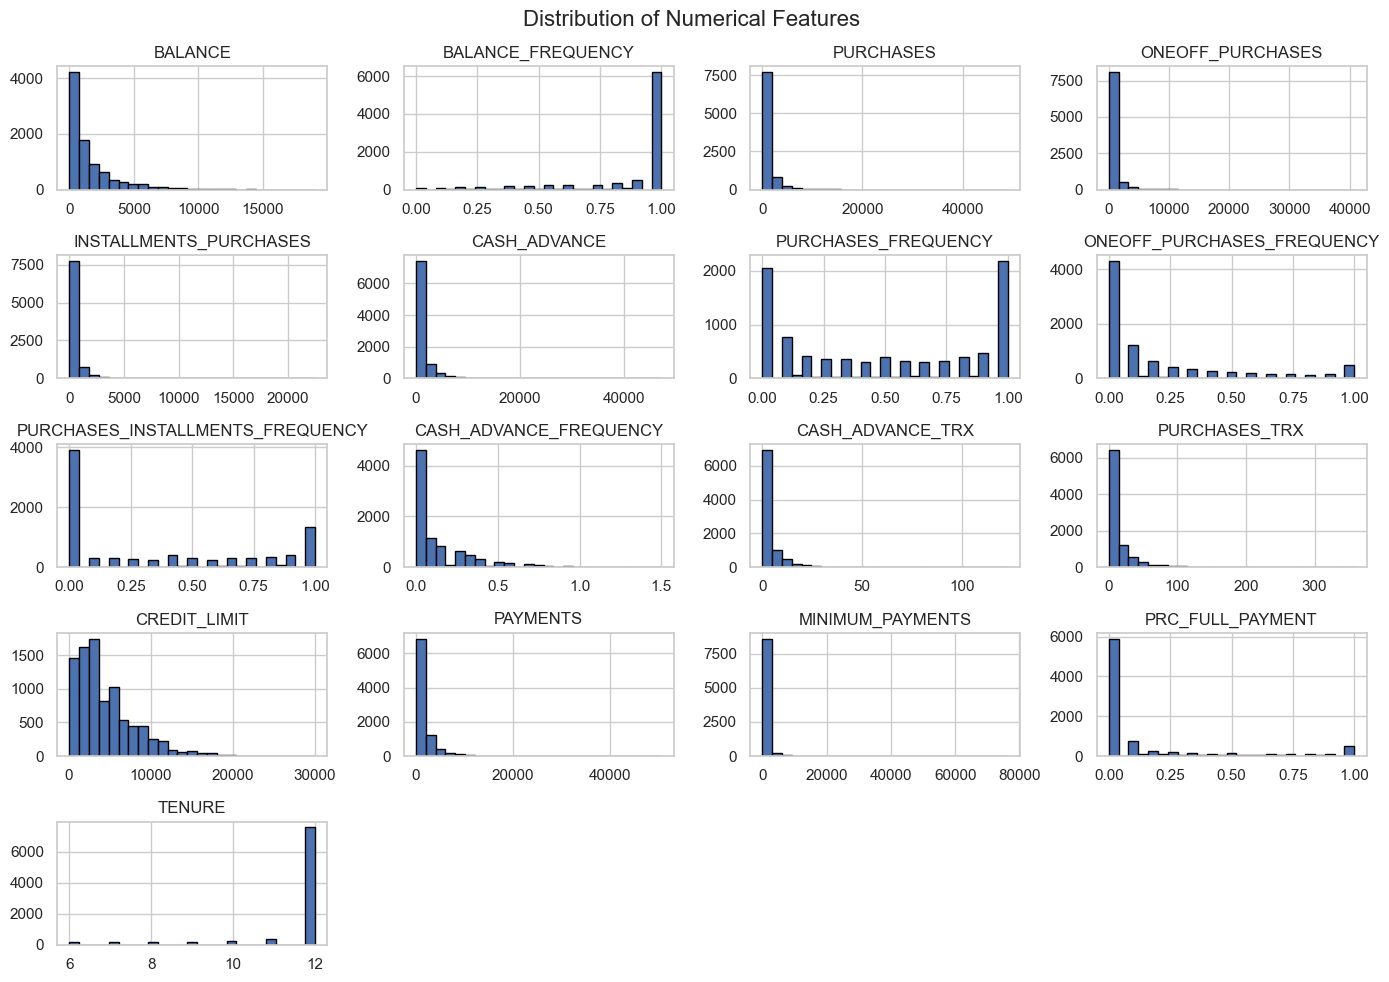

In [6]:

numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

if not numeric_columns:
    raise ValueError("No numerical features found in the dataset.")

df_clean[numeric_columns].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


## Correlation heatmap

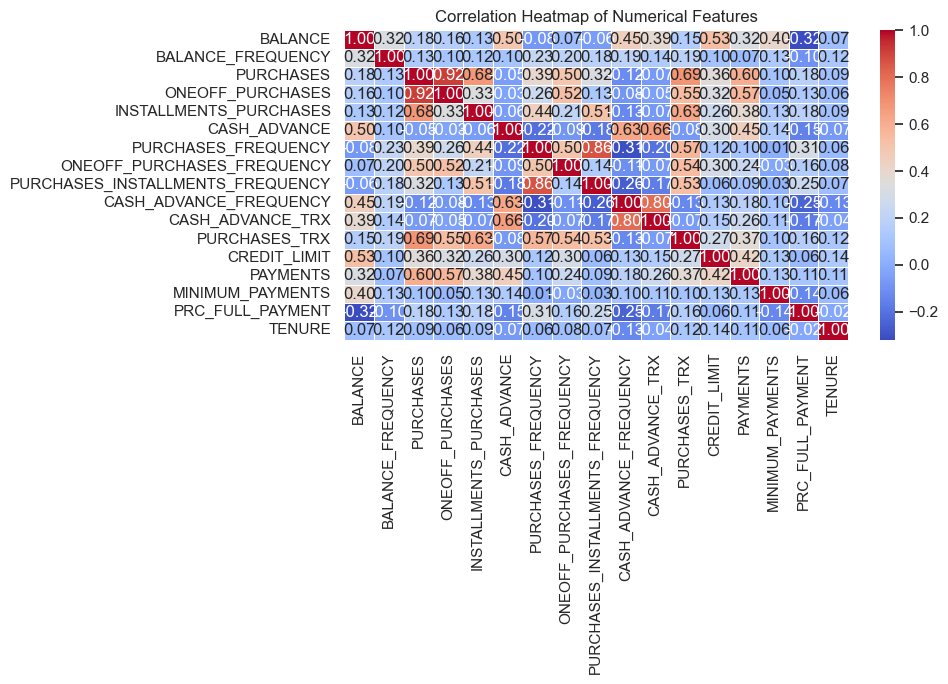

In [7]:

correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


## Outlier inspection

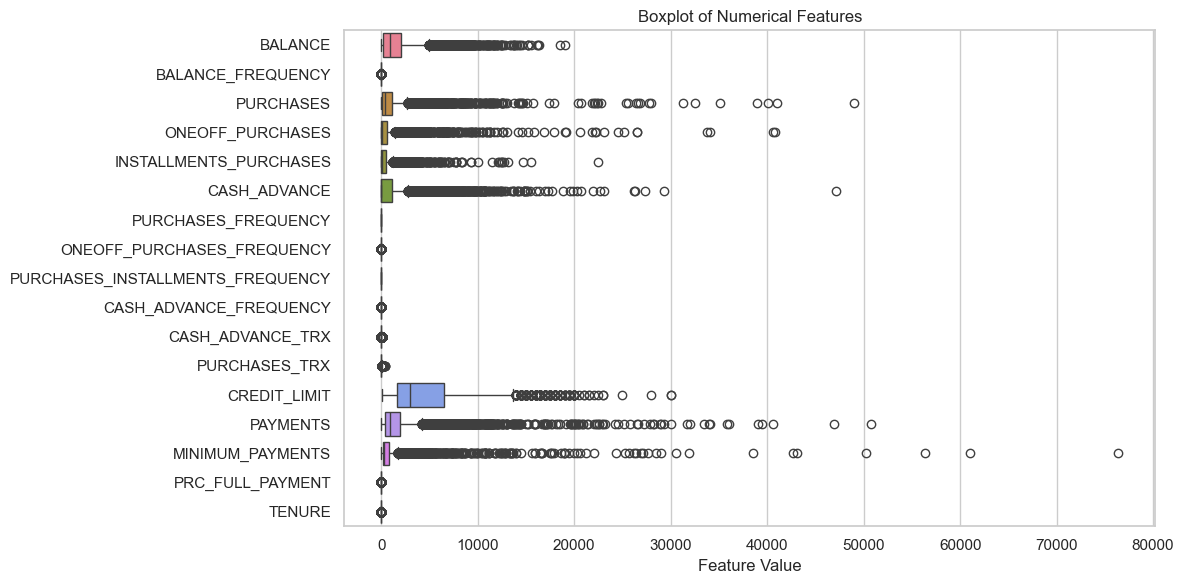

In [8]:

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_clean[numeric_columns], orient="h")

plt.title("Boxplot of Numerical Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()



### EDA Observations

Review the histograms and record which features are skewed or have a wide range of values.

Use the correlation heatmap to identify strongly related numerical features. The boxplots help flag possible outliers, but these observations should be checked against the dataset's meaning before removing any values.

These observations will guide feature selection and scaling.



## PART-2 (Feature selection)

Clustering should use attributes that describe the observations meaningfully.

Identifier columns, such as customer IDs, will be excluded because their numerical values do not represent customer similarity. Ground-truth labels or known categories will also be excluded from model fitting and retained separately only if needed for post-clustering interpretation.

Suitable numerical features and relevant categorical attributes will be selected for preprocessing.


## Prepare the clustering features

In [9]:

# Review these columns after running the cell.
# Add or remove exclusions according to your actual dataset.
EXCLUDE_COLUMNS = []  # Example: ["CustomerID", "Channel", "Region"]

# Exclude common identifier and ground-truth label columns automatically.
def is_identifier_or_label(column):
    name = column.lower().replace(" ", "").replace("-", "").replace("_", "")
    keywords = [
        "id", "groundtruth", "truecluster",
        "target", "label", "class"
    ]
    return any(keyword in name for keyword in keywords)

automatic_exclusions = [
    col for col in df_clean.columns
    if is_identifier_or_label(col)
]

excluded_columns = list(set(EXCLUDE_COLUMNS + automatic_exclusions))
excluded_columns = [
    col for col in excluded_columns if col in df_clean.columns
]

candidate_df = df_clean.drop(columns=excluded_columns)

# Select numeric and categorical features
numeric_features = candidate_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = candidate_df.select_dtypes(
    exclude=np.number
).columns.tolist()

# One-hot encode categorical features
X_encoded = pd.get_dummies(
    candidate_df[numeric_features + categorical_features],
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

# Remove constant columns
constant_columns = [
    col for col in X_encoded.columns
    if X_encoded[col].nunique() <= 1
]
X_encoded = X_encoded.drop(columns=constant_columns)

if X_encoded.shape[1] < 2:
    raise ValueError(
        "At least two non-constant clustering features are required. "
        "Check the excluded columns and dataset."
    )

if len(X_encoded) < 3:
    raise ValueError("At least three observations are required.")

print("Excluded columns:", excluded_columns)
print("Numerical features:", numeric_features)
print("Categorical features encoded:", categorical_features)
print("Constant columns removed:", constant_columns)
print("Final feature count:", X_encoded.shape[1])

display(X_encoded.head())


Excluded columns: ['CUST_ID']
Numerical features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
Categorical features encoded: []
Constant columns removed: []
Final feature count: 17


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.343947,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



## Feature Scaling

K-Means and Agglomerative Clustering are distance-based algorithms. Features with large numerical ranges may dominate the distance calculation if scaling is not applied.

StandardScaler transforms each feature to have approximately zero mean and unit variance. This gives features measured on different scales a more comparable influence.

Because this is an unsupervised clustering task, the scaler is fitted to the observations used for clustering. No ground-truth labels are used to fit the scaler or clustering models.



## Apply Standard Scaler



In [10]:

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X_encoded)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X_encoded.columns,
    index=X_encoded.index
)

print("Scaled dataset shape:", X_scaled.shape)

print("\nFeature means after scaling:")
display(X_scaled.mean().round(3).to_frame("Mean"))

print("\nFeature standard deviations after scaling:")
display(X_scaled.std(ddof=0).round(3).to_frame("Standard Deviation"))


Scaled dataset shape: (8950, 17)

Feature means after scaling:


,Mean
BALANCE,0.0
BALANCE_FREQUENCY,0.0
PURCHASES,0.0
ONEOFF_PURCHASES,0.0
INSTALLMENTS_PURCHASES,0.0
CASH_ADVANCE,0.0
PURCHASES_FREQUENCY,-0.0
ONEOFF_PURCHASES_FREQUENCY,-0.0
PURCHASES_INSTALLMENTS_FREQUENCY,0.0
CASH_ADVANCE_FREQUENCY,0.0



Feature standard deviations after scaling:


,Standard Deviation
BALANCE,1.0
BALANCE_FREQUENCY,1.0
PURCHASES,1.0
ONEOFF_PURCHASES,1.0
INSTALLMENTS_PURCHASES,1.0
CASH_ADVANCE,1.0
PURCHASES_FREQUENCY,1.0
ONEOFF_PURCHASES_FREQUENCY,1.0
PURCHASES_INSTALLMENTS_FREQUENCY,1.0
CASH_ADVANCE_FREQUENCY,1.0


### Part-3


##  K-Means Clustering

K-Means is an unsupervised algorithm that partitions observations into k clusters. Each observation is assigned to the cluster whose centroid is closest to it.

The algorithm repeatedly assigns observations to centroids and updates the centroids until the assignments stabilize or the stopping condition is reached.

### Elbow Method

The Elbow method plots the number of clusters against inertia, which is the sum of squared distances from observations to their assigned centroids.

Inertia generally decreases as the number of clusters increases. The elbow point is a candidate for the number of clusters, but the final decision will also consider internal evaluation metrics and the usefulness of the resulting groups.


### Elbow Curve

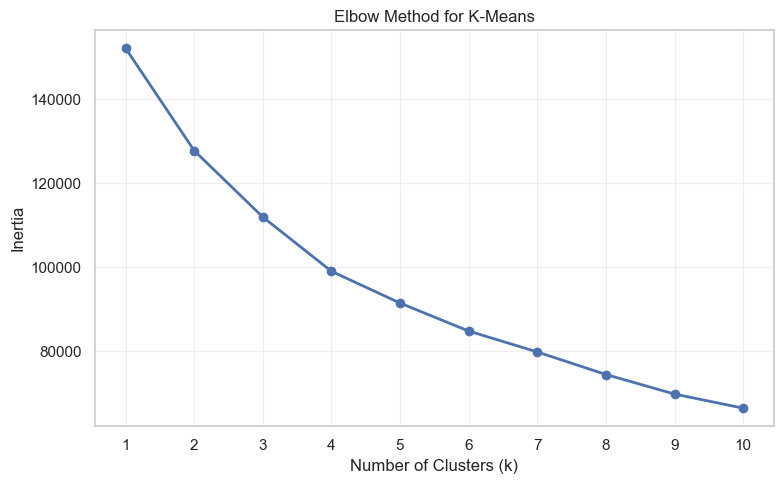

In [11]:

max_k = min(10, len(X_scaled) - 1)

if max_k < 2:
    raise ValueError("Not enough observations to test multiple clusters.")

k_values = list(range(2, max_k + 1))
inertias = []

for k in range(1, max_k + 1):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, max_k + 1),
    inertias,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, max_k + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### K-Means evaluation metrics


### Evaluation Metrics

The following metrics will be used to compare possible K-Means solutions:

- **Silhouette Score:** Measures how well an observation fits within its cluster compared with other clusters. Higher values are generally better.
- **Davies-Bouldin Index:** Compares within-cluster scatter with separation between clusters. Lower values are generally better.
- **Calinski-Harabasz Index:** Compares between-cluster dispersion with within-cluster dispersion. Higher values are generally better.

The metrics provide complementary evidence and should be interpreted together.



###  Define the evaluation function

In [12]:

def evaluate_clustering(X, labels):
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels)

    if n_clusters < 2 or n_clusters >= len(X):
        return {
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    return {
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }

print("Evaluation function defined.")



Evaluation function defined.



### Evaluate different values of k

In [13]:

kmeans_models = {}
kmeans_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = model

    metrics = evaluate_clustering(X_scaled, labels)

    kmeans_results.append({
        "Algorithm": "K-Means",
        "Clusters": k,
        "Inertia": model.inertia_,
        **metrics
    })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(4))


,Algorithm,Clusters,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,2,127784.5345,0.2100,1.9120,1706.1790
1,K-Means,3,111975.0436,0.2510,1.5920,1605.0264
2,K-Means,4,99061.9398,0.1977,1.5748,1598.0769
3,K-Means,5,91490.4980,0.1931,1.5492,1482.6682
4,K-Means,6,84826.5920,0.2029,1.5064,1419.6994
5,K-Means,7,79856.1570,0.2077,1.4918,1349.3508
6,K-Means,8,74484.8801,0.2217,1.3697,1331.9734
7,K-Means,9,69828.6993,0.2260,1.2943,1317.5722
8,K-Means,10,66466.4149,0.2204,1.3631,1280.5318



### Select a candidate K-Means model

In [14]:

valid_kmeans = kmeans_results_df.dropna(
    subset=["Silhouette Score"]
)

if valid_kmeans.empty:
    raise ValueError("No valid K-Means solution was found.")

# Use Silhouette Score to identify a candidate, then compare it
# with the Elbow curve and the other evaluation metrics.
best_k = int(
    valid_kmeans.loc[
        valid_kmeans["Silhouette Score"].idxmax(),
        "Clusters"
    ]
)

kmeans_model = kmeans_models[best_k]
kmeans_labels = kmeans_model.labels_

print("Candidate K-Means cluster count:", best_k)
print("\nCluster sizes:")
display(
    pd.Series(kmeans_labels)
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number of Observations")
)


Candidate K-Means cluster count: 3

Cluster sizes:


,Number of Observations
Cluster,
0,1275
1,6114
2,1561



### K-Means Interpretation

Compare the candidate cluster count selected by Silhouette Score with the Elbow curve. Review the Davies-Bouldin and Calinski-Harabasz indices as well.

The selected number of clusters should be justified using the observed results, not only by choosing the highest score. If the Elbow curve suggests a different value, compare the alternatives before finalizing the model.



##  Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a bottom-up clustering algorithm. Each observation initially forms its own cluster, and the algorithm repeatedly merges the closest clusters until the required number of clusters remains.

### Linkage Strategies

- **Ward linkage:** Merges clusters to minimize the increase in within-cluster variance.
- **Complete linkage:** Uses the maximum pairwise distance between two clusters.
- **Average linkage:** Uses the average pairwise distance between two clusters.

Comparing linkage strategies helps us understand how different definitions of cluster distance affect the final segmentation.


In [15]:

linkage_strategies = ["ward", "complete", "average"]

hierarchical_models = {}
hierarchical_results = []

for method in linkage_strategies:
    for k in k_values:
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method
        )

        labels = model.fit_predict(X_scaled)
        hierarchical_models[(method, k)] = model

        metrics = evaluate_clustering(X_scaled, labels)

        hierarchical_results.append({
            "Algorithm": "Agglomerative",
            "Linkage": method,
            "Clusters": k,
            **metrics
        })

hierarchical_results_df = pd.DataFrame(hierarchical_results)

display(
    hierarchical_results_df
    .sort_values("Silhouette Score", ascending=False)
    .round(4)
)


,Algorithm,Linkage,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
18,Agglomerative,average,2,0.8408,0.1103,60.3699
19,Agglomerative,average,3,0.8126,0.1233,52.1508
20,Agglomerative,average,4,0.8080,0.2649,90.7405
9,Agglomerative,complete,2,0.7866,0.5902,698.3770
10,Agglomerative,complete,3,0.7863,0.4836,384.2692
21,Agglomerative,average,5,0.7857,0.4599,253.8662
11,Agglomerative,complete,4,0.7792,0.4927,339.8114
22,Agglomerative,average,6,0.7565,0.6467,214.7623
23,Agglomerative,average,7,0.7565,0.5677,181.7177
24,Agglomerative,average,8,0.7157,0.6944,187.8855



### Dendrogram Visualization

A dendrogram displays the order in which observations or clusters are merged. The vertical axis indicates the distance at which a merge occurs.

Large vertical gaps can suggest possible places to cut the hierarchy and obtain a smaller number of clusters.

For readability, the dendrogram may use a deterministic sample of observations when the dataset is large. The clustering evaluation metrics, however, are calculated on the full dataset.


##  Plot the dendrogram

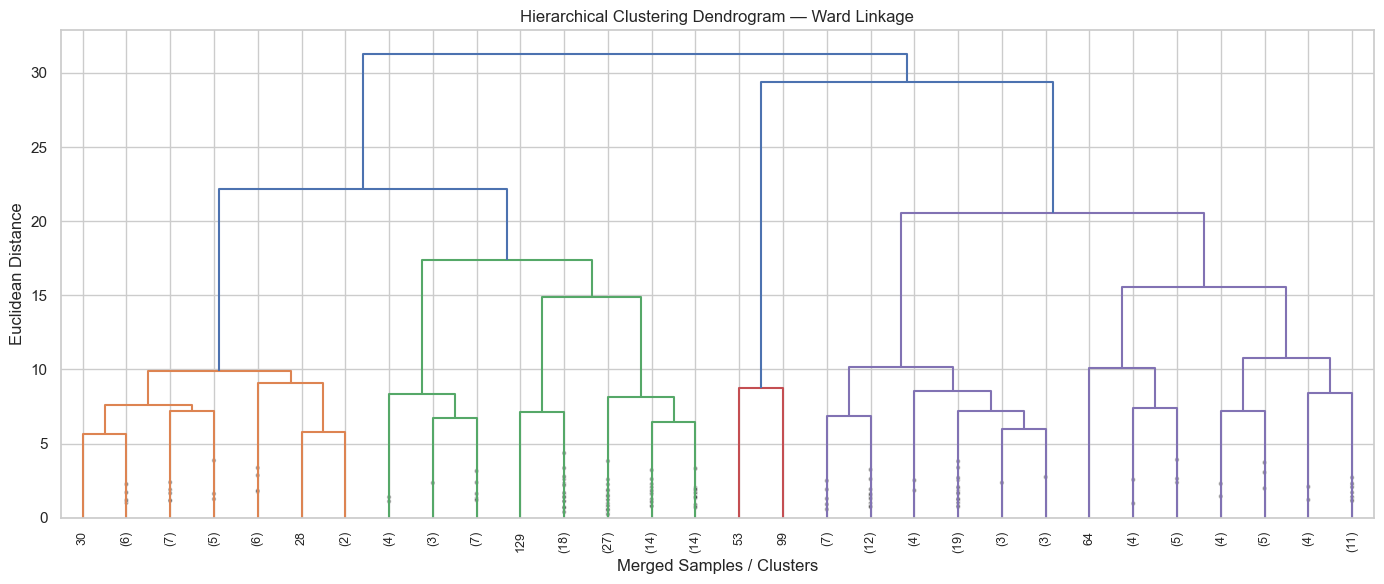

In [16]:

sample_size = min(200, len(X_scaled))

X_dendrogram = X_scaled.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

Z = linkage(
    X_dendrogram,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram — Ward Linkage")
plt.xlabel("Merged Samples / Clusters")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()


## Select the hierarchical model

In [17]:

valid_hierarchical = hierarchical_results_df.dropna(
    subset=["Silhouette Score"]
)

if valid_hierarchical.empty:
    raise ValueError("No valid hierarchical solution was found.")

best_hierarchical_row = valid_hierarchical.loc[
    valid_hierarchical["Silhouette Score"].idxmax()
]

best_linkage = best_hierarchical_row["Linkage"]
best_hierarchical_k = int(best_hierarchical_row["Clusters"])

hierarchical_model = hierarchical_models[
    (best_linkage, best_hierarchical_k)
]

hierarchical_labels = hierarchical_model.labels_

print("Candidate linkage:", best_linkage)
print("Candidate number of clusters:", best_hierarchical_k)

print("\nCluster sizes:")
display(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number of Observations")
)


Candidate linkage: average
Candidate number of clusters: 2

Cluster sizes:


,Number of Observations
Cluster,
0,8949
1,1



### Hierarchical Clustering Interpretation

Compare the Silhouette Scores for the different linkage strategies and cluster counts. Also review the Davies-Bouldin and Calinski-Harabasz indices.

The dendrogram provides a visual view of the hierarchy, while the metrics provide numerical evidence about cluster quality. The final choice should consider both sources of information.


### Part 5 — Final evaluation and visualization


##  Final Model Comparison

The candidate K-Means and Agglomerative models will be compared using the three required internal clustering metrics.

Silhouette Score is generally better when higher, Davies-Bouldin Index is generally better when lower, and Calinski-Harabasz Index is generally better when higher.

The metrics will be considered together when discussing the relative strengths and limitations of the models.


###  Final comparision table

In [18]:

final_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": best_k,
        "Linkage": "Not applicable",
        **evaluate_clustering(X_scaled, kmeans_labels)
    },
    {
        "Algorithm": "Agglomerative",
        "Clusters": best_hierarchical_k,
        "Linkage": best_linkage,
        **evaluate_clustering(X_scaled, hierarchical_labels)
    }
])

display(final_comparison.round(4))


,Algorithm,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,Not applicable,0.2510,1.5920,1605.0264
1,Agglomerative,2,average,0.8408,0.1103,60.3699



## PCA Cluster Visualization


Principal Component Analysis (PCA) transforms the scaled features into principal components that capture the greatest possible variance.

The first two principal components will be used to visualize the cluster assignments from each algorithm in two dimensions.

PCA is used only for visualization in this step. The clustering algorithms are fitted on the scaled feature data, not on the PCA coordinates.


In [19]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print(
    f"PC1 variance explained: {explained_variance[0] * 100:.2f}%"
)
print(
    f"PC2 variance explained: {explained_variance[1] * 100:.2f}%"
)
print(
    "Total variance explained by two components: "
    f"{explained_variance.sum() * 100:.2f}%"
)


PC1 variance explained: 27.30%
PC2 variance explained: 20.31%
Total variance explained by two components: 47.61%


## PCA plots for both algorithms


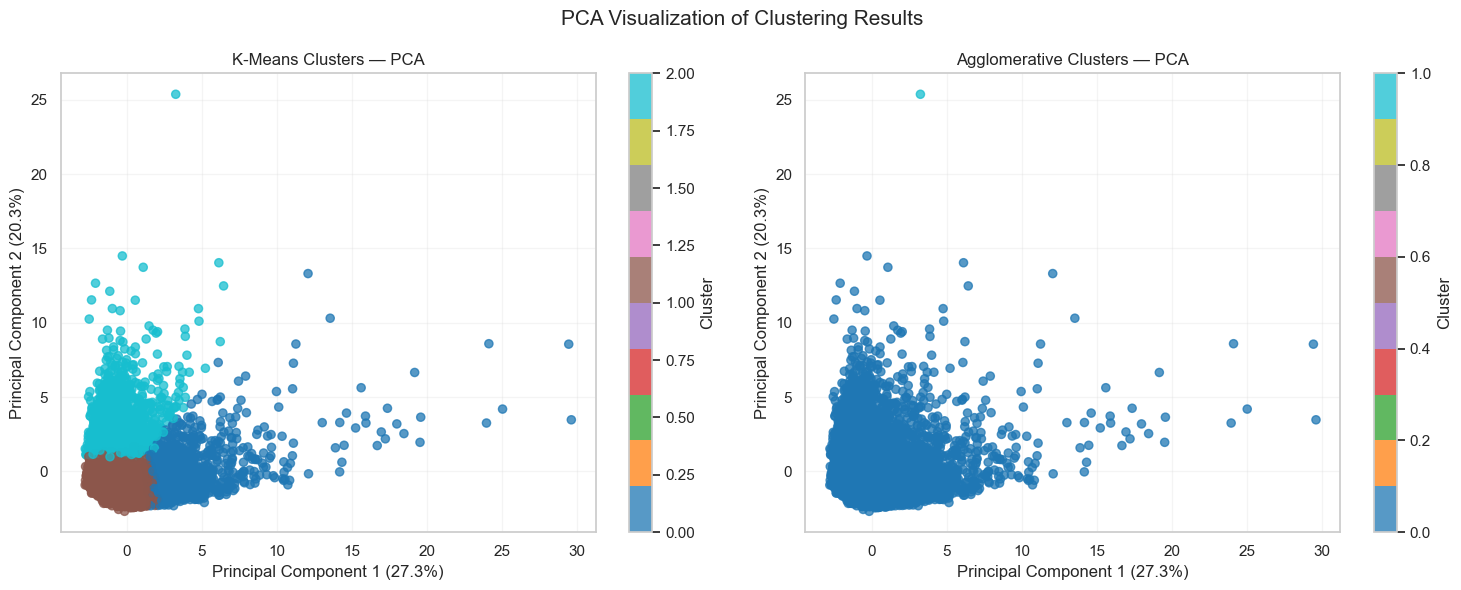

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cluster_results = [
    ("K-Means", kmeans_labels),
    ("Agglomerative", hierarchical_labels)
]

for ax, (name, labels) in zip(axes, cluster_results):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab10",
        s=35,
        alpha=0.75
    )

    ax.set_title(f"{name} Clusters — PCA")
    ax.set_xlabel(
        f"Principal Component 1 ({explained_variance[0] * 100:.1f}%)"
    )
    ax.set_ylabel(
        f"Principal Component 2 ({explained_variance[1] * 100:.1f}%)"
    )
    ax.grid(alpha=0.2)

    fig.colorbar(scatter, ax=ax, label="Cluster")

fig.suptitle("PCA Visualization of Clustering Results", fontsize=15)
plt.tight_layout()
plt.show()



### PCA Visualization Observations

Compare the PCA plots and describe the apparent separation, overlap, compactness and size of the clusters.

The percentage of variance explained by the two principal components should be considered when interpreting the plots. Since PCA reduces the dimensionality to two components, some structure present in the original features may not be visible.

Write conclusions based on the actual plots rather than assuming that one algorithm is better.



## Additional Visualization Using t-SNE

t-distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality-reduction technique used to visualize high-dimensional data in two dimensions.

The t-SNE visualization will show the selected K-Means cluster assignments. It is included as an additional visualization and will not be used to train or select the clustering model.

Unlike PCA, t-SNE emphasizes local neighborhood relationships, so distances between separated groups should not be interpreted as direct measurements of cluster quality.


## Generate the t-SNE plot

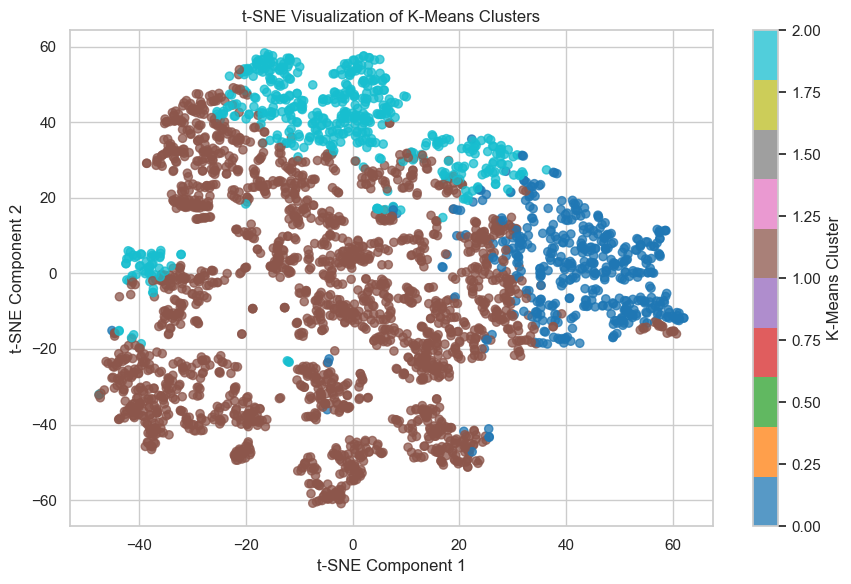

In [21]:

# Use a deterministic sample if the dataset is large.
tsne_max_samples = 3000

if len(X_scaled) > tsne_max_samples:
    rng = np.random.RandomState(RANDOM_STATE)
    tsne_indices = np.sort(
        rng.choice(len(X_scaled), size=tsne_max_samples, replace=False)
    )
else:
    tsne_indices = np.arange(len(X_scaled))

X_tsne_input = X_scaled.iloc[tsne_indices]
tsne_labels = np.asarray(kmeans_labels)[tsne_indices]

if len(X_tsne_input) < 4:
    raise ValueError("At least four observations are required for t-SNE.")

perplexity = min(30, max(2, (len(X_tsne_input) - 1) // 3))

tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=tsne_labels,
    cmap="tab10",
    s=35,
    alpha=0.75
)

plt.title("t-SNE Visualization of K-Means Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(scatter, label="K-Means Cluster")
plt.tight_layout()
plt.show()



##  Cluster Profiling and Interpretation

Cluster profiling helps explain the characteristics of the groups identified by the clustering algorithms.

We will summarize the original numerical features for each K-Means cluster. The cluster numbers are identifiers assigned by the algorithm; they do not indicate a ranking or a meaningful order.

Interpretations should be based on the feature values and the domain represented by the dataset.



## Create cluster profiles



In [22]:

cluster_profile_data = df_clean.loc[
    X_encoded.index, numeric_features
].copy()

cluster_profile_data["KMeans_Cluster"] = kmeans_labels

cluster_profiles = cluster_profile_data.groupby(
    "KMeans_Cluster"
).mean()

print("Mean numerical feature values for each K-Means cluster:")
display(cluster_profiles.round(2))


Mean numerical feature values for each K-Means cluster:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
KMeans_Cluster,,,,,,,,,,,,,,,,,
0,2182.35,0.98,4187.02,2664.00,1523.49,449.75,0.95,0.66,0.74,0.06,1.51,55.69,7642.78,4075.53,1227.92,0.30,11.92
1,807.72,0.83,496.06,247.27,249.11,339.00,0.46,0.13,0.34,0.07,1.24,8.48,3267.02,907.45,530.07,0.15,11.48
2,4023.79,0.96,389.05,252.33,136.80,3917.25,0.23,0.11,0.15,0.45,12.55,5.64,6729.47,3053.94,1765.20,0.03,11.35



## Compare cluster sizes

Cluster sizes for the two selected models:


,K-Means,Agglomerative
0,1275,8949
1,6114,1
2,1561,0


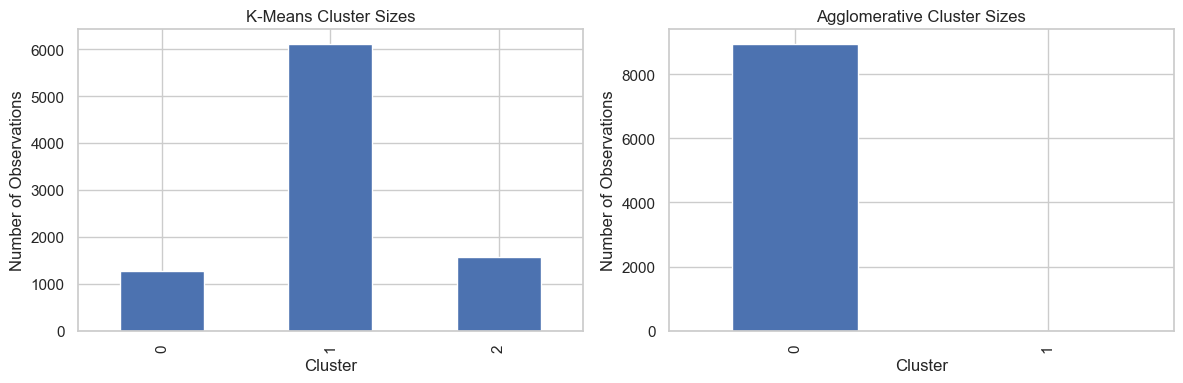

In [23]:

cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Agglomerative": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster sizes for the two selected models:")
display(cluster_sizes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pd.Series(kmeans_labels).value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("K-Means Cluster Sizes")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of Observations")

pd.Series(hierarchical_labels).value_counts().sort_index().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Agglomerative Cluster Sizes")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()



## 17. Conclusion

This project applied K-Means and Agglomerative Hierarchical Clustering to explore groups within the selected dataset.

The Elbow method was used to examine candidate cluster counts for K-Means. Agglomerative clustering was evaluated using multiple linkage strategies, and a dendrogram was used to inspect the hierarchical structure.

The candidate models were compared using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. PCA and t-SNE were used to visualize the resulting cluster assignments.

### Final Interpretation

Complete the following points after examining the actual results:

1. State the candidate number of clusters selected for K-Means and explain why.
2. State the selected linkage and number of clusters for Agglomerative Clustering.
3. Compare the internal evaluation metrics of the two models.
4. Describe the main differences between the groups using the cluster profiles.
5. Discuss the limitations of the analysis, including sensitivity to scaling, outliers, and the selected features.

The final preferred model should be justified using the metrics, visualizations and interpretability of the resulting groups rather than a single score alone.


### PART-6-Final checks and submission

In [24]:

print("=" * 60)
print("CLUSTERING PROJECT FINAL SUMMARY")
print("=" * 60)

print("\nDataset shape:", df_clean.shape)
print("Features used:", X_scaled.shape[1])
print("Random state:", RANDOM_STATE)

print("\nK-Means")
print("Number of clusters:", best_k)
print("Cluster labels obtained:", len(np.unique(kmeans_labels)))

print("\nAgglomerative Hierarchical Clustering")
print("Linkage:", best_linkage)
print("Number of clusters:", best_hierarchical_k)
print("Cluster labels obtained:", len(np.unique(hierarchical_labels)))

print("\nFinal metric comparison:")
display(final_comparison.round(4))

assert len(kmeans_labels) == len(X_scaled)
assert len(hierarchical_labels) == len(X_scaled)

print("\nBoth clustering algorithms completed successfully.")


CLUSTERING PROJECT FINAL SUMMARY

Dataset shape: (8950, 18)
Features used: 17
Random state: 42

K-Means
Number of clusters: 3
Cluster labels obtained: 3

Agglomerative Hierarchical Clustering
Linkage: average
Number of clusters: 2
Cluster labels obtained: 2

Final metric comparison:


,Algorithm,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,Not applicable,0.2510,1.5920,1605.0264
1,Agglomerative,2,average,0.8408,0.1103,60.3699



Both clustering algorithms completed successfully.



##  References and Acknowledgements

- Scikit-learn documentation: https://scikit-learn.org/stable/
- Pandas documentation: https://pandas.pydata.org/docs/
- SciPy hierarchical clustering documentation: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html

AI assistance was used for coding guidance and notebook structure. The dataset-specific analysis, interpretation of the results, and final conclusions should be reviewed and validated by the project team.
